In [1]:
import numpy as np, time
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

images = np.load(r"D:\Resplan\resplan_64.npy")      # (17000, 64, 64), values 0-11
N_CLASSES = 12                                        # empty + 11 room/part types

# 90% for training, 10% held back to test on plans the model never saw
rng = np.random.default_rng(0)
idx = rng.permutation(len(images))
n_val = len(images) // 10
val_idx, train_idx = idx[:n_val], idx[n_val:]

X = torch.from_numpy(images).long()
train_dl = DataLoader(TensorDataset(X[train_idx]), batch_size=128, shuffle=True)
val_dl   = DataLoader(TensorDataset(X[val_idx]),   batch_size=256)

# Rare classes (doors, stairs) get more weight so the model doesn't ignore them
freq = np.bincount(images[train_idx].ravel(), minlength=N_CLASSES) / images[train_idx].size
w = 1 / np.sqrt(freq + 1e-6)
w = np.clip(w / w.min(), None, 10)
class_weights = torch.tensor(w, dtype=torch.float32)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Train plans:", len(train_idx), "| Test plans:", len(val_idx))
print("Running on:", device)
print("Class weights:", np.round(w, 1))

Train plans: 15300 | Test plans: 1700
Running on: cpu
Class weights: [ 1.   1.8  1.7  3.4  3.7  3.9 10.  10.   2.   5.5  4.5 10. ]


In [2]:
class FloorPlanAE(nn.Module):
    def __init__(self, n_classes=N_CLASSES, latent=64):
        super().__init__()
        def down(i, o): return nn.Sequential(nn.Conv2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.ReLU())
        def up(i, o):   return nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.ReLU())
        self.n_classes = n_classes
        self.encoder = nn.Sequential(
            down(n_classes, 32), down(32, 64), down(64, 128), down(128, 256),   # 64 → 4 pixels
            nn.Flatten(), nn.Linear(256 * 4 * 4, latent))
        self.decoder = nn.Sequential(
            nn.Linear(latent, 256 * 4 * 4), nn.Unflatten(1, (256, 4, 4)),
            up(256, 128), up(128, 64), up(64, 32),                               # 4 → 32 pixels
            nn.ConvTranspose2d(32, n_classes, 4, 2, 1))                          # → 64, one score per class

    def encode(self, x):            # x: (batch, 64, 64) class numbers
        x = F.one_hot(x, self.n_classes).permute(0, 3, 1, 2).float()
        return self.encoder(x)

    def forward(self, x):
        return self.decoder(self.encode(x))

model = FloorPlanAE().to(device)

# Quick test with 4 plans
out = model(X[:4].to(device))
print("Input:", tuple(X[:4].shape), "→ latent:", tuple(model.encode(X[:4].to(device)).shape),
      "→ output:", tuple(out.shape))
print("Model size:", sum(p.numel() for p in model.parameters()) // 1000, "thousand parameters")

Input: (4, 64, 64) → latent: (4, 64) → output: (4, 12, 64, 64)
Model size: 1919 thousand parameters


In [3]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))
EPOCHS = 15
best = float("inf")
history = []

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    # --- learn from the training plans ---
    model.train()
    train_loss = 0
    for (xb,) in train_dl:
        xb = xb.to(device)
        loss = loss_fn(model(xb), xb)       # how badly did it rebuild the plan?
        opt.zero_grad(); loss.backward(); opt.step()
        train_loss += loss.item() * len(xb)
    train_loss /= len(train_idx)

    # --- test on plans it has never seen ---
    model.eval()
    val_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for (xb,) in val_dl:
            xb = xb.to(device)
            out = model(xb)
            val_loss += loss_fn(out, xb).item() * len(xb)
            pred = out.argmax(1)
            m = xb > 0                       # only score pixels that are part of the home
            correct += (pred[m] == xb[m]).sum().item()
            total += m.sum().item()
    val_loss /= len(val_idx)
    acc = correct / total
    history.append((train_loss, val_loss, acc))

    # --- keep the best version so far ---
    if val_loss < best:
        best = val_loss
        torch.save(model.state_dict(), r"D:\Resplan\ae_64_best.pt")

    print(f"Epoch {epoch:2}/{EPOCHS} | train loss {train_loss:.3f} | test loss {val_loss:.3f} "
          f"| room accuracy {acc:.1%} | {time.time() - t0:.0f}s")

Epoch  1/15 | train loss 1.442 | test loss 0.932 | room accuracy 66.8% | 46s
Epoch  2/15 | train loss 0.754 | test loss 0.644 | room accuracy 74.9% | 104s
Epoch  3/15 | train loss 0.587 | test loss 0.547 | room accuracy 78.3% | 95s
Epoch  4/15 | train loss 0.504 | test loss 0.487 | room accuracy 80.2% | 106s
Epoch  5/15 | train loss 0.456 | test loss 0.462 | room accuracy 80.6% | 109s
Epoch  6/15 | train loss 0.419 | test loss 0.432 | room accuracy 81.3% | 102s
Epoch  7/15 | train loss 0.396 | test loss 0.411 | room accuracy 82.6% | 96s
Epoch  8/15 | train loss 0.376 | test loss 0.406 | room accuracy 82.8% | 116s
Epoch  9/15 | train loss 0.365 | test loss 0.397 | room accuracy 82.6% | 114s
Epoch 10/15 | train loss 0.353 | test loss 0.390 | room accuracy 83.7% | 95s
Epoch 11/15 | train loss 0.342 | test loss 0.385 | room accuracy 83.8% | 115s
Epoch 12/15 | train loss 0.333 | test loss 0.386 | room accuracy 83.7% | 118s
Epoch 13/15 | train loss 0.324 | test loss 0.374 | room accuracy 84.

How often each type is rebuilt correctly (test plans):
  empty       95%
  living      94%
  bedroom     95%
  kitchen     95%
  bathroom    90%
  balcony     93%
  storage     77%
  stair       60%
  wall        56%
  door        61%
  window      65%
  front_door  78%


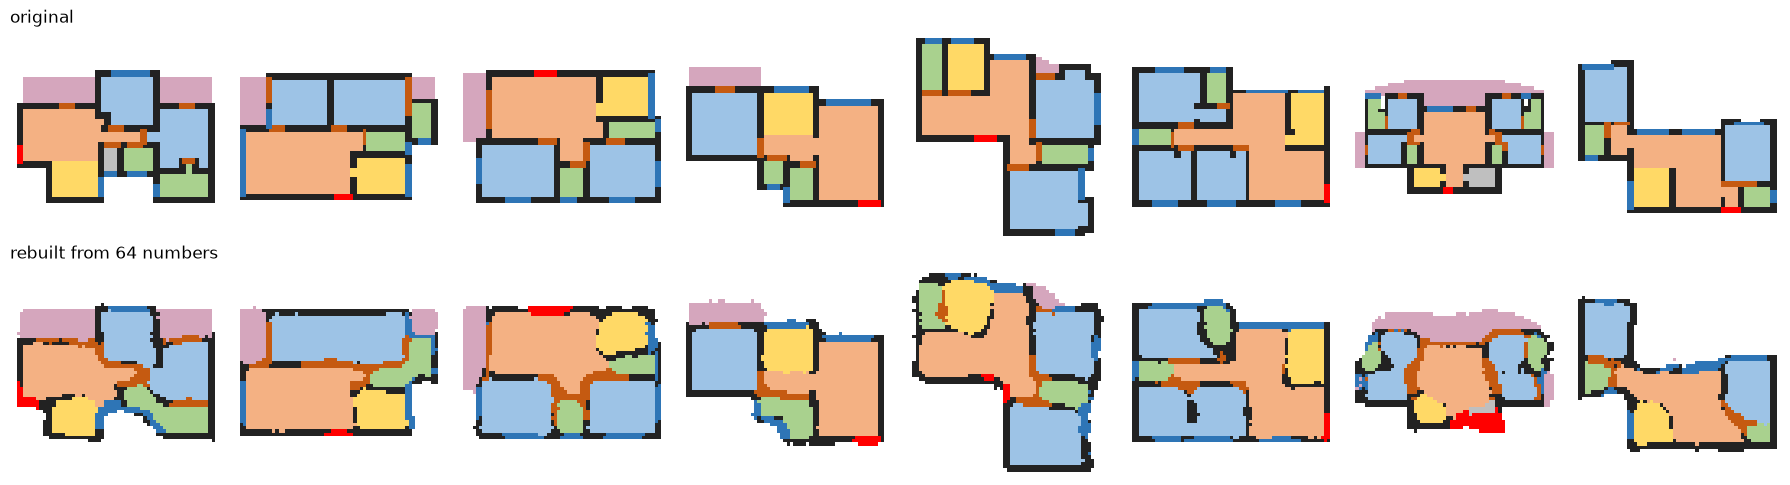

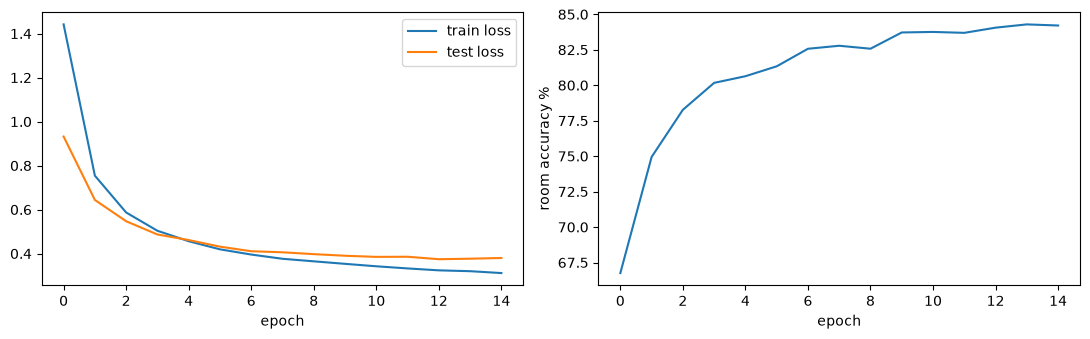

In [4]:
from matplotlib.colors import ListedColormap

CLASS_NAMES = ["empty", "living", "bedroom", "kitchen", "bathroom", "balcony",
               "storage", "stair", "wall", "door", "window", "front_door"]
cmap = ListedColormap(["#ffffff", "#f4b183", "#9dc3e6", "#ffd966", "#a9d18e", "#d5a6bd",
                       "#bfbfbf", "#8e7cc3", "#222222", "#c55a11", "#2e75b6", "#ff0000"])

# Load the best saved model
model.load_state_dict(torch.load(r"D:\Resplan\ae_64_best.pt", map_location=device))
model.eval()

# Rebuild all test plans
with torch.no_grad():
    pred = torch.cat([model(xb.to(device)).argmax(1).cpu() for (xb,) in val_dl])
true = X[val_idx]

# 1. Accuracy per room type
print("How often each type is rebuilt correctly (test plans):")
for c, name in enumerate(CLASS_NAMES):
    m = true == c
    print(f"  {name:11} {(pred[m] == c).float().mean():.0%}")

# 2. Original vs rebuilt, 8 test plans
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for j in range(8):
    axes[0, j].imshow(true[j], cmap=cmap, vmin=0, vmax=11, interpolation="nearest")
    axes[1, j].imshow(pred[j], cmap=cmap, vmin=0, vmax=11, interpolation="nearest")
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("rebuilt from 64 numbers", loc="left")
plt.tight_layout(); plt.savefig("reconstructions.png", dpi=120); plt.show()

# 3. Training curve
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h[:, 0], label="train loss"); ax[0].plot(h[:, 1], label="test loss"); ax[0].legend()
ax[0].set_xlabel("epoch"); ax[1].plot(h[:, 2] * 100); ax[1].set_ylabel("room accuracy %")
ax[1].set_xlabel("epoch"); plt.tight_layout(); plt.savefig("training_curve.png", dpi=120); plt.show()

## Results: Autoencoder v1
- Input: 64×64 floor plans, 12 classes (empty + 11 room/part types), 15,300 train / 1,700 test plans.
- Model: convolutional autoencoder, latent size 64, 1.9M parameters, 15 epochs (~25 min on CPU).
- Loss: cross-entropy with class weights (1/√frequency, capped at 10) so rare parts are not ignored.
- **Test room accuracy: 84%** (pixels inside the home rebuilt with the correct room type).
- Rebuilt plans keep the outline and room placement; rooms become rounded, and doors are
  over-predicted (side effect of the class weights).
- Model saved locally as `ae_64_best.pt` (to be uploaded to Hugging Face).

**Next ideas:** lower the door weight, try latent 128, train longer with a learning-rate schedule.